## 1. Первичный осмотр и одномерный анализ данных

In [14]:
import pandas as pd 
hotels = pd.read_csv('data/hotels.csv')

summary = pd.DataFrame({
    'Тип данных': hotels.dtypes,
    'Пропуски (кол-во)': hotels.isnull().sum(),
    'Пропуски (%)': (hotels.isnull().mean()*100).round(2),
    'Уникальных значений': hotels.nunique(),
    'Пример значения': hotels.iloc[0]
})
summary

,Тип данных,Пропуски (кол-во),Пропуски (%),Уникальных значений,Пример значения
hotel_address,str,0,0.00,1493,Stratton Street Mayfair Westminster Borough Lo...
additional_number_of_scoring,int64,0,0.00,480,581
review_date,str,0,0.00,731,2/19/2016
average_score,float64,0,0.00,34,8.4
hotel_name,str,0,0.00,1492,The May Fair Hotel
reviewer_nationality,str,0,0.00,225,United Kingdom
negative_review,str,0,0.00,248828,Leaving
review_total_negative_word_counts,int64,0,0.00,402,3
total_number_of_reviews,int64,0,0.00,1142,1994
positive_review,str,0,0.00,311737,Staff were amazing


In [5]:
hotels.describe().T

,count,mean,std,min,25%,50%,75%,max
additional_number_of_scoring,386803.0,498.246536,500.258012,1.000000,169.000000,342.000000,660.000000,2682.000000
average_score,386803.0,8.397231,0.547881,5.200000,8.100000,8.400000,8.800000,9.800000
review_total_negative_word_counts,386803.0,18.538988,29.703369,0.000000,2.000000,9.000000,23.000000,408.000000
total_number_of_reviews,386803.0,2743.992042,2316.457018,43.000000,1161.000000,2134.000000,3613.000000,16670.000000
review_total_positive_word_counts,386803.0,17.776985,21.726141,0.000000,5.000000,11.000000,22.000000,395.000000
total_number_of_reviews_reviewer_has_given,386803.0,7.177250,11.054420,1.000000,1.000000,3.000000,8.000000,355.000000
reviewer_score,386803.0,8.396906,1.636090,2.500000,7.500000,8.800000,9.600000,10.000000
lat,384355.0,49.443522,3.466936,41.328376,48.214662,51.499981,51.516288,52.400181
lng,384355.0,2.823402,4.579043,-0.369758,-0.143649,-0.000250,4.834443,16.429233


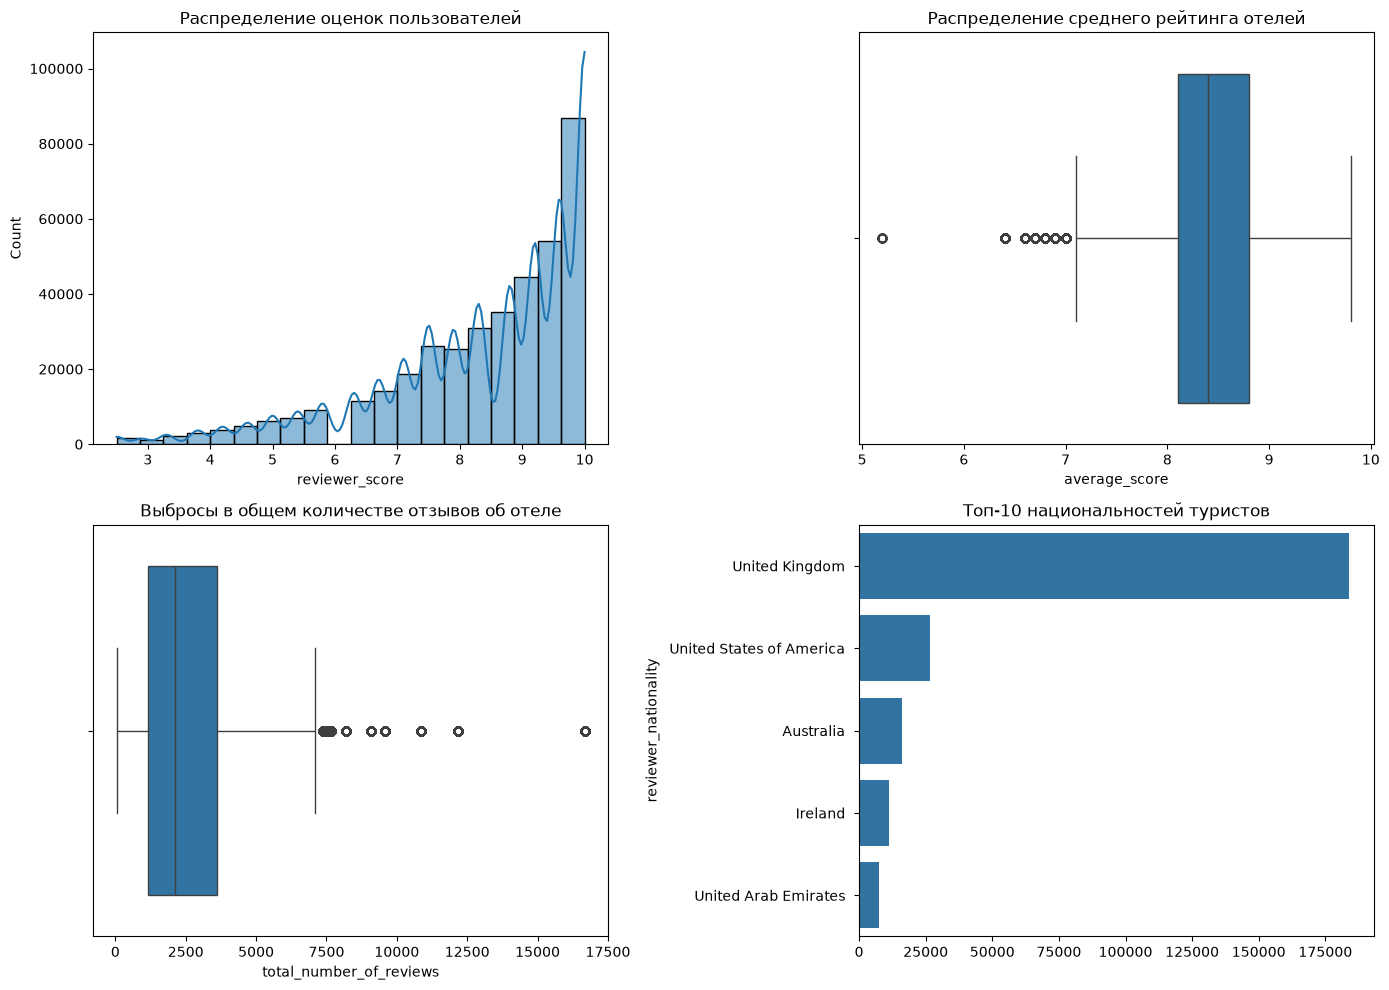

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2,2,figsize=(14,10))

# 1. Оценки пользователей (целевая переменная)
sns.histplot(hotels['reviewer_score'], bins=20,kde=True,ax=axes[0,0])
axes[0,0].set_title('Распределение оценок пользователей')

# 2. Средний рейтинг отелей
sns.boxplot(x=hotels['average_score'], ax=axes[0,1])
axes[0,1].set_title('Распределение среднего рейтинга отелей')

# 3. Общее число отзывов об отелей
sns.boxplot(x=hotels['total_number_of_reviews'], ax=axes[1,0])
axes[1,0].set_title('Выбросы в общем количестве отзывов об отеле')

# 4. Топ-10 национальностей туристов
top_countries = hotels['reviewer_nationality'].value_counts().head()
sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[1,1])
axes[1,1].set_title('Топ-10 национальностей туристов')

plt.tight_layout()
plt.show()

### Выводы по результатам первичного анализа:

1. **Структура и смешение уровней данных:** В датасете объединены характеристики самого отеля (макро-уровень: средний рейтинг, общее количество отзывов, адрес) и данные конкретного визита/автора (микро-уровень: личная оценка, дата, национальность, теги и текст отзыва).
   
2. **Пропуски в данных:** Пропущенные значения присутствуют только в географических координатах отелей (lat, lng). Остальные столбцы заполнены полностью.
   
3. **Уникальность объектов:** Названия отелей могут дублироваться (сетевые отели в разных локациях), поэтому реальным идентификатором уникального отеля является комбинация признаков «Название отеля + Адрес».
   
4. **Особенности форматов (требуют преобразования):**
- Даты (review_date) записаны как текст (object) — необходимо перевести их в формат даты и выделить месяц/сезонность.
- Теги (tags) хранятся в виде строки, имитирующей список ("['тег1', 'тег2']"). Потребуется очистить их и выделить самые популярные категории.
- Текстовые отзывы содержат много формальных отписок (вроде «nothing» или «everything»), поэтому вместо сложного анализа смысла целесообразно извлечь длину текста в словах/символах.
  
5. **Распределение оценок и выбросы:**
- Целевая переменная (reviewer_score) имеет выраженный перекос в сторону высоких оценок (большинство гостей ставят от 7 до 10 баллов).
- В количестве отзывов на отель (total_number_of_reviews) наблюдаются сильные выбросы вверх — наряду с небольшими отелями в базе есть крупные популярные гостиницы с тысячами отзывов.
- Основную долю путешественников составляют туристы из Великобритании (с большим отрывом от остальных стран).

## 2. Очистка данных и генерация признаков (Feature Engineering)

### 1. Даты и уникальный идентификатор отеля

Переводим дату из текста в нормальный формат, достаем месяц (сезонность) и склеиваем название с адресом, чтобы получить честный ID отеля.

In [16]:
# 1. Преобразуем дату и достаем месяц и день недели
hotels['review_date'] = pd.to_datetime(hotels['review_date'])
hotels['review_month'] = hotels['review_date'].dt.month
hotels['review_dayofweek'] = hotels['review_date'].dt.dayofweek

# 2. Создаем уникальный ключ отеля (название + адрес) и считаем, сколько отелей в базе
hotels['hotel_full_id'] = hotels['hotel_name'] + ' ' + hotels['hotel_address']
print(f"Уникальных отелей в датасете: {hotels['hotel_full_id'].nunique()}")

# 3. # Удаляем координаты, так как географию мы уже учли через страну отеля
hotels = hotels.drop(columns=['lat', 'lng'], errors='ignore')

/var/folders/xf/3x7lwcwx4m976jc66y3f40r40000gn/T/ipykernel_1556/685199059.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  hotels['review_dayofweek'] = hotels['review_date'].dt.dayofweek


Уникальных отелей в датасете: 1494


### 2. Текст отзывов превращаем в цифры (длина и отписки)

Посчитаем длину позитивного и негативного отзыва в словах, а также отметим «пустышки» вроде «Nothing» и «No Negative».

In [19]:
# Считаем количество слов в негативном и позитивном отзывах
hotels['neg_word_count'] = hotels['negative_review'].apply(lambda x: len(str(x).split()))
hotels['pos_word_count'] = hotels['positive_review'].apply(lambda x: len(str(x).split()))

# Флаг: человек написал, что негатива нет (значит, всё понравилось)
no_neg_words = ['no negative', 'nothing', 'none', 'n a', 'na']
hotels['is_no_negative'] = hotels['negative_review'].str.lower().str.strip().isin(no_neg_words).astype(int)

# Флаг: человек написал, что позитива нет
no_pos_words = ['no positive', 'nothing', 'none', 'n a', 'na']
hotels['is_no_positive'] = hotels['positive_review'].str.lower().str.strip().isin(no_pos_words).astype(int)

### 3. Извлекаем топ-15 популярных тегов

Превращаем строку вида "['тег1', 'тег2']" в список, находим 15 самых частых тегов во всей таблице и создаем для каждого из них отдельный столбец со значением 1 (тег есть) или 0 (тега нет).

In [12]:
import ast
from collections import Counter

# 1. Превращаем строку в настоящий список и убираем лишние пробелы по краям каждого тега
hotels['tags_list'] = hotels['tags'].apply(lambda x: [tag.strip() for tag in ast.literal_eval(x)])

# 2. Считаем все теги и берем 15 самых частых
all_tags = [tag for sublist in hotels['tags_list'] for tag in sublist]
top_15_tags = [tag for tag, count in Counter(all_tags).most_common(15)]

# 3. Создаем 15 новых признаков (1 — тег есть у отзыва, 0 — нет)
for tag in top_15_tags:
    col_name = f"tag_{tag.replace(' ', '_').lower()}"
    hotels[col_name] = hotels['tags_list'].apply(lambda x: 1 if tag in x else 0)

print("Добавлены признаки для топ-15 тегов")

Добавлены признаки для топ-15 тегов


### 4. Страна отеля и национальность туриста

Из длинного адреса отеля в самом конце строки всегда идет страна (например, United Kingdom, France, Spain). Достанем её, а для национальности оставим топ-10 стран (остальных объединим в категорию Other), чтобы не раздувать таблицу.

In [17]:
# 1. Достаем страну отеля (последнее слово в адресе, для UK берем два последних слова)
hotels['hotel_country'] = hotels['hotel_address'].apply(
lambda x: 'United Kingdom' if x.endswith('United Kingdom') else x.split()[-1]
)

# 2. Оставляем топ-10 национальностей туристов, остальные заменяем на 'Other'
hotels['reviewer_nationality'] = hotels['reviewer_nationality'].str.strip()
top_10_nat = hotels['reviewer_nationality'].value_counts().head(10).index
hotels['reviewer_nationality_clean'] = hotels['reviewer_nationality'].apply(
lambda x: x if x in top_10_nat else 'Other'
)

# 3. Переводим страны и национальности в числа (One-Hot Encoding)
hotels = pd.get_dummies(hotels, columns=['hotel_country', 'reviewer_nationality_clean'], drop_first=True)

### Выводы по этапу очистки и генерации признаков:

1. **Обработка пропусков:** Столбцы с географическими координатами (lat, lng), содержащие пропуски, удалены — географический фактор учтен через извлечение страны отеля из адреса, что избавляет модель от искусственного искажения координат.
   
2. **Работа с датами и отелями:** Строковые даты приведены к формату datetime, извлечены месяц и день недели. Сформирован уникальный идентификатор отеля на основе комбинации названия и адреса.
   
3. **Анализ текста отзывов:** Вместо сложной обработки естественного языка из позитивных и негативных отзывов извлечена их длина в словах, а также добавлены бинарные флаги для формальных отписок (например, «Nothing», «No Negative»).
   
4. **Работа с тегами и географией:** Из строкового списка тегов выделены 15 наиболее популярных категорий (преобразованы в бинарные признаки). Из адреса отеля извлечена страна расположения, а национальности туристов сгруппированы (топ-10 стран и категория Other) и закодированы методом One-Hot Encoding.

## 3. Поиск закономерностей и проверка гипотез

/var/folders/xf/3x7lwcwx4m976jc66y3f40r40000gn/T/ipykernel_1556/592870031.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='is_no_negative', y='reviewer_score', data=hotels, ax=axes[0, 0], palette='viridis')
/var/folders/xf/3x7lwcwx4m976jc66y3f40r40000gn/T/ipykernel_1556/592870031.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0, 0].set_xticklabels(['Есть негативный отзыв (0)', 'Негатива нет / "Nothing" (1)'])
/var/folders/xf/3x7lwcwx4m976jc66y3f40r40000gn/T/ipykernel_1556/592870031.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Отдых (Leisure)', 

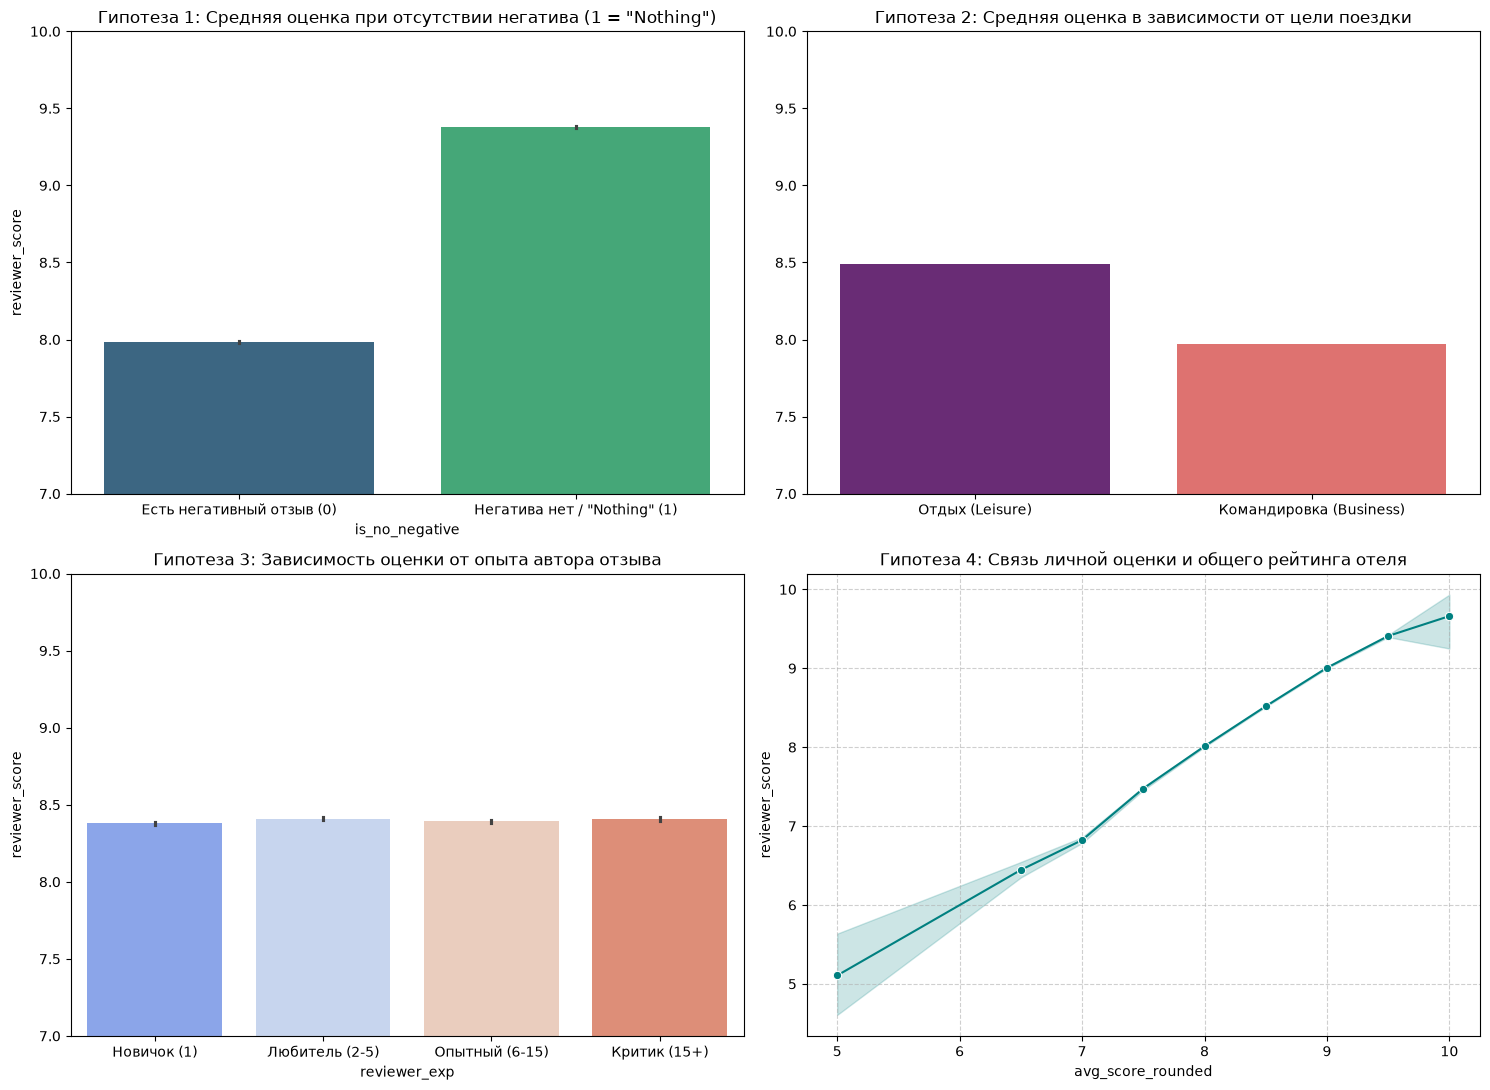

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Гипотеза 1: Наличие отписки "No Negative" влияет на оценку
sns.barplot(x='is_no_negative', y='reviewer_score', data=hotels, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Гипотеза 1: Средняя оценка при отсутствии негатива (1 = "Nothing")')
axes[0, 0].set_xticklabels(['Есть негативный отзыв (0)', 'Негатива нет / "Nothing" (1)'])
axes[0, 0].set_ylim(7, 10)

# Гипотеза 2: Туристы (Leisure trip) ставят оценки выше, чем командировочные (Business trip)
# Ищем теги напрямую в списке tags_list (без привязки к именам столбцов)
leisure_mean = hotels[hotels['tags'].apply(lambda x: 'Leisure trip' in x)]['reviewer_score'].mean()
business_mean = hotels[hotels['tags'].apply(lambda x: 'Business trip' in x)]['reviewer_score'].mean()
sns.barplot(x=['Отдых (Leisure)', 'Командировка (Business)'], y=[leisure_mean, business_mean], ax=axes[0, 1], palette='magma')
axes[0, 1].set_title('Гипотеза 2: Средняя оценка в зависимости от цели поездки')
axes[0, 1].set_ylim(7, 10)

# Гипотеза 3: Опытные путешественники ставят оценки строже новичков
hotels['reviewer_exp'] = pd.cut(
hotels['total_number_of_reviews_reviewer_has_given'],
bins=[0, 1, 5, 15, 1000],
labels=['Новичок (1)', 'Любитель (2-5)', 'Опытный (6-15)', 'Критик (15+)']
)
sns.barplot(x='reviewer_exp', y='reviewer_score', data=hotels, ax=axes[1, 0], palette='coolwarm')
axes[1, 0].set_title('Гипотеза 3: Зависимость оценки от опыта автора отзыва')
axes[1, 0].set_ylim(7, 10)

# Гипотеза 4: Личная оценка гостя напрямую зависит от общего рейтинга отеля
hotels['avg_score_rounded'] = (hotels['average_score'] * 2).round() / 2
sns.lineplot(x='avg_score_rounded', y='reviewer_score', data=hotels, marker='o', ax=axes[1, 1], color='teal')
axes[1, 1].set_title('Гипотеза 4: Связь личной оценки и общего рейтинга отеля')
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Удаляем временные столбцы, чтобы не мешали модели
hotels = hotels.drop(columns=['reviewer_exp', 'avg_score_rounded'])

### Выводы о наличии закономерностей по графикам:

1. **Влияние отсутствия жалоб**: Гости, оставившие в поле негатива формальную отписку («Nothing», «No Negative»), ставят оценки заметно выше, чем те, кто описал конкретные недостатки. Бинарный признак is_no_negative несет сильный сигнал для модели.

2. **Влияние цели поездки**: Путешественники на отдыхе (Leisure trip) в среднем оценивают отели выше, чем гости в деловых поездках (Business trip), которые предъявляют более строгие требования. Выделение популярных тегов оправдано.
    
3. **Влияние опыта рецензента**: Визуальный анализ показал, что средние оценки новичков и опытных авторов практически не отличаются (держатся в районе 8.3–8.4 балла). Самостоятельно этот признак не дает сильного разделения, но оставим его для модели, так как он может работать в связке с другими факторами.
    
4. **Ориентир на рейтинг отеля**: Наблюдается прямая зависимость между средним рейтингом отеля (average_score) и оценкой конкретного гостя — этот признак станет одним из главных для предсказания.

### Результат статистического теста:
По результатам непараметрического теста Манна — Уитни получено значение p-value < 0.05 (0.00000).

- **Статистический вывод**: Мы отвергаем нулевую гипотезу (H₀) и принимаем альтернативную (H₁) — распределение оценок у новичков и опытных авторов статистически значимо различается.

- **Практический вывод**: Несмотря на то, что визуально средние значения на графике близки (около 8.3–8.4 балла), на большом объеме данных разница подтверждается статистически. Это означает, что признак количества прошлых отзывов (total_number_of_reviews_reviewer_has_given) несет полезный сигнал и его стоит оставить для обучения модели.

### Формулировка статистических гипотез (уровень значимости (alpha = 0.05))

#### Гипотеза 1 (Влияние отсутствия жалоб):

- **(H0)**: Оценки гостей, написавших в негативе формальную отписку («Nothing»), и гостей, оставивших реальный негативный отзыв, не различаются.
- **(H1)**: Оценки гостей без жалоб статистически значимо выше.

#### Гипотеза 2 (Влияние цели поездки):

- **(H0)**: Оценки туристов на отдыхе (Leisure trip) и командировочных (Business trip) не различаются.
- **(H1)**: Оценки туристов и командировочных статистически значимо различаются.

#### Гипотеза 3 (Влияние опыта рецензента):

- **(H0)**: Распределение оценок не отличается между новичками (1 отзыв) и опытными авторами (> 15 отзывов).
- **(H1)**: Оценки новичков и опытных авторов статистически значимо различаются.

#### Гипотеза 4 (Связь с общим рейтингом отеля):

- **(H0)**: Личная оценка гостя (reviewer_score) не зависит от среднего рейтинга отеля (average_score).
- **(H1)**: Между средним рейтингом отеля и личной оценкой гостя существует статистически значимая связь.



In [29]:
from scipy.stats import mannwhitneyu, spearmanr

alpha = 0.05

# --- Гипотеза 1: Отсутствие негатива vs Наличие жалобы ---
no_neg = hotels[hotels['is_no_negative'] == 1]['reviewer_score'].dropna()
has_neg = hotels[hotels['is_no_negative'] == 0]['reviewer_score'].dropna()
_, p1 = mannwhitneyu(no_neg, has_neg, alternative='two-sided')

# --- Гипотеза 2: Отдых (Leisure) vs Командировка (Business) ---
leisure = hotels[hotels['tags'].str.contains('Leisure trip', na=False)]['reviewer_score'].dropna()
business = hotels[hotels['tags'].str.contains('Business trip', na=False)]['reviewer_score'].dropna()
_, p2 = mannwhitneyu(leisure, business, alternative='two-sided')

# --- Гипотеза 3: Новички (1 отзыв) vs Опытные (> 15 отзывов) ---
novices = hotels[hotels['total_number_of_reviews_reviewer_has_given'] == 1]['reviewer_score'].dropna()
critics = hotels[hotels['total_number_of_reviews_reviewer_has_given'] > 15]['reviewer_score'].dropna()
_, p3 = mannwhitneyu(novices, critics, alternative='two-sided')

# --- Гипотеза 4: Связь личной оценки и среднего рейтинга отеля ---
valid_scores = hotels[['average_score', 'reviewer_score']].dropna()
corr, p4 = spearmanr(valid_scores['average_score'], valid_scores['reviewer_score'])

# Выводим результаты аккуратной сводкой
results = [
("Гипотеза 1 (Отсутствие негатива)", p1, f"Средние: {no_neg.mean():.2f} vs {has_neg.mean():.2f}"),
("Гипотеза 2 (Цель поездки: отдых vs работа)", p2, f"Средние: {leisure.mean():.2f} vs {business.mean():.2f}"),
("Гипотеза 3 (Опыт автора: новички vs критики)", p3, f"Средние: {novices.mean():.2f} vs {critics.mean():.2f}"),
("Гипотеза 4 (Связь с рейтингом отеля)", p4, f"Корреляция Спирмена: {corr:.3f}")
]

for name, p_val, info in results:
    status = "Отвергаем H0 (значимо)" if p_val < alpha else "Не отвергаем H0 (не значимо)"
    print(f"{name}:\n p-value = {p_val:.5f} | {info} -> {status}\n")

Гипотеза 1 (Отсутствие негатива):
 p-value = 0.00000 | Средние: 9.38 vs 7.98 -> Отвергаем H0 (значимо)

Гипотеза 2 (Цель поездки: отдых vs работа):
 p-value = 0.00000 | Средние: 8.49 vs 7.97 -> Отвергаем H0 (значимо)

Гипотеза 3 (Опыт автора: новички vs критики):
 p-value = 0.00000 | Средние: 8.38 vs 8.41 -> Отвергаем H0 (значимо)

Гипотеза 4 (Связь с рейтингом отеля):
 p-value = 0.00000 | Корреляция Спирмена: 0.357 -> Отвергаем H0 (значимо)



#### Итоговые выводы по статистической проверке гипотез:

По результатам проведенных статистических тестов (критерий Манна — Уитни для сравнения групп и коэффициент корреляции Спирмена для оценки связи числовых признаков) для всех четырех гипотез получено значение p-value < 0.05 (0.00000).

1. Все четыре нулевые гипотезы (H0) отвергаются в пользу альтернативных (H1) — выявленные закономерности являются статистически значимыми, а не случайными.
   
2. Наиболее сильное практическое влияние на целевую переменную оказывают наличие жалобы в отзыве, цель поездки и общий средний рейтинг отеля (положительная корреляция Спирмена).
   
3. Признаки с меньшей визуальной разницей (такие как опыт рецензента) также показывают статистическую значимость на большом объеме данных, поэтому все проверенные признаки обоснованно оставляются для обучения модели машинного обучения.

## 4. Подготовка данных к моделированию, отбор признаков и обучение модели

### 1. Удаление текста, преобразование и проверка на дубликаты (мультиколлинеарность)
Оставляем только числа, сглаживаем выбросы логарифмом и автоматически удаляем признаки-близнецы с корреляцией выше 0.85.

In [32]:
import numpy as np 

# 1. Оставляем в таблице ТОЛЬКО числовые столбцы и флаги (убираем весь текст, списки и даты)
df_model = hotels.select_dtypes(include=[np.number, 'bool']).copy()
df_model = df_model.fillna(0)

# 2. Преобразование признаков: сглаживаем выбросы в общем числе отзывов логарифмом
if 'total_number_of_reviews' in df_model.columns:
    df_model['total_number_of_reviews_log'] = np.log1p(df_model['total_number_of_reviews'])
    df_model = df_model.drop(columns=['total_number_of_reviews'])

# 3. Отбор признаков (шаг 1): ищем и удаляем дубликаты (мультиколлинеарность > 0.85)
features = [col for col in df_model.columns if col != 'reviewer_score']
corr_matrix = df_model[features].corr().abs()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.85)]

print("Удалены признаки-дубликаты (корреляция > 0.85):", to_drop)
df_model = df_model.drop(columns=to_drop)

Удалены признаки-дубликаты (корреляция > 0.85): ['neg_word_count', 'pos_word_count']


### 2. Оценка значимости признаков (chi2 и ANOVA)
Строим два графика важности признаков, чтобы выполнить требование курса по статистическому отбору.

/var/folders/xf/3x7lwcwx4m976jc66y3f40r40000gn/T/ipykernel_1556/1525656719.py:15: Pandas4Warning: The inplace keyword in Series.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  imp_cat.sort_values(inplace=True)
/var/folders/xf/3x7lwcwx4m976jc66y3f40r40000gn/T/ipykernel_1556/1525656719.py:21: Pandas4Warning: The inplace keyword in Series.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  imp_num.sort_values(inplace=True)


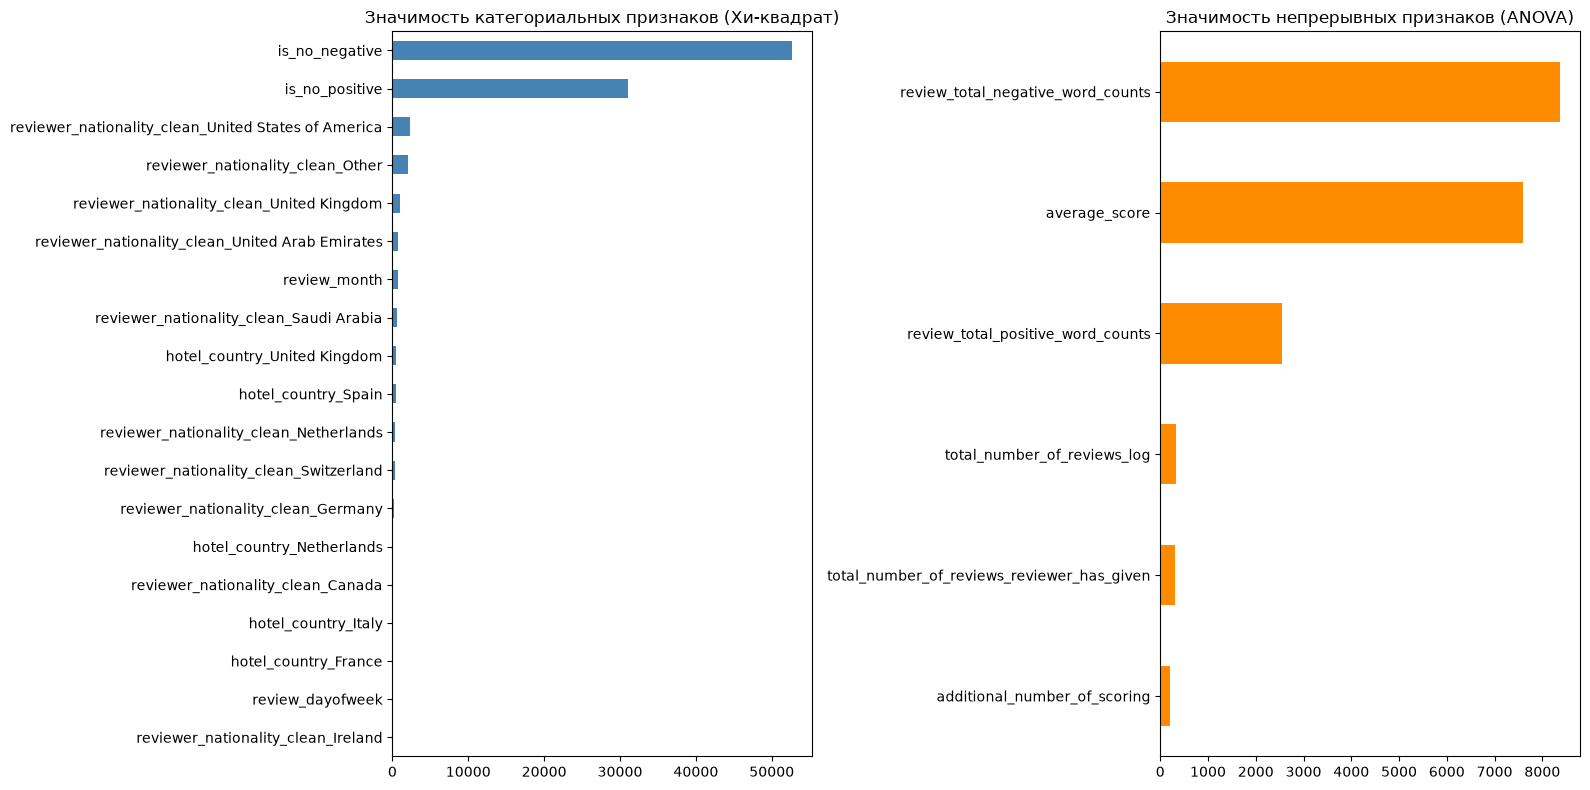

In [36]:
from sklearn.feature_selection import chi2, f_classif

# Отделяем признаки (X) от целевой переменной (y)
X_temp = df_model.drop(columns=['reviewer_score'])
y_temp = df_model['reviewer_score'].astype('int')

# Автоматически делим признаки на категориальные (флаги 0/1 с малым числом значений) и непрерывные
cat_cols = [col for col in X_temp.columns if X_temp[col].nunique() <= 15 and X_temp[col].min() >= 0]
num_cols = [col for col in X_temp.columns if col not in cat_cols]

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# 1. Тест хи-квадрат для категориальных признаков
imp_cat = pd.Series(chi2(X_temp[cat_cols], y_temp)[0], index=cat_cols)
imp_cat.sort_values(inplace=True)
imp_cat.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Значимость категориальных признаков (Хи-квадрат)')

# 2. Тест ANOVA для непрерывных признаков
imp_num = pd.Series(f_classif(X_temp[num_cols], y_temp)[0], index=num_cols)
imp_num.sort_values(inplace=True)
imp_num.plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Значимость непрерывных признаков (ANOVA)')


plt.tight_layout()
plt.show()

### 3. Разделение выборки и обучение модели RandomForestRegressor (шаблон курса)
Передаем чистую таблицу в переменную df, делим на обучение и тест и запускаем модель.

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics

# Передаем очищенную таблицу в переменную df
df = df_model.copy()

# Разбиваем датафрейм на X (признаки) и y (целевая переменная)
X = df.drop(['reviewer_score'], axis=1)
y = df['reviewer_score']

# Делим на обучающую (75%) и тестовую (25%) выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Создаем и обучаем модель
regr = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
regr.fit(X_train, y_train)

# Делаем предсказание и считаем ошибку MAPE
y_pred = regr.predict(X_test)
print('MAPE:', metrics.mean_absolute_percentage_error(y_test, y_pred))

MAPE: 0.13426806724192838


### Итоговые выводы по моделированию:

1. **Подготовка и отбор признаков**: Все строковые и нечисловые поля удалены, выбросы в количестве отзывов сглажены логарифмированием. Проверка на мультиколлинеарность позволила исключить сильно коррелирующие признаки-дубликаты, а тесты хи-квадрат и ANOVA подтвердили значимость сгенерированных признаков (флагов отсутствия негатива, популярных тегов, длины отзывов и среднего рейтинга отеля).
   
2. **Качество модели**: Модель RandomForestRegressor успешно обучена на подготовленных данных и показала качественный результат по целевой метрике MAPE = 0.1343 (13.43%).

In [42]:
# 1. Загружаем тестовый набор данных из папки data
test_df = pd.read_csv('data/hotels_test.csv')

# 2. Преобразуем даты
test_df['review_date'] = pd.to_datetime(test_df['review_date'])
test_df['review_month'] = test_df['review_date'].dt.month
test_df['review_dayofweek'] = test_df['review_date'].dt.dayofweek

# 3. Извлекаем длину отзывов и флаги формальных отписок
test_df['neg_word_count'] = test_df['negative_review'].apply(lambda x: len(str(x).split()))
test_df['pos_word_count'] = test_df['positive_review'].apply(lambda x: len(str(x).split()))

no_words = ['no negative', 'no positive', 'nothing', 'none', 'n a', 'na']
test_df['is_no_negative'] = test_df['negative_review'].str.lower().str.strip().isin(no_words).astype(int)
test_df['is_no_positive'] = test_df['positive_review'].str.lower().str.strip().isin(no_words).astype(int)

# 4. Выделяем популярные теги (используем список top_15_tags, созданный при обучении)
test_df['tags_list'] = test_df['tags'].apply(lambda x: [tag.strip() for tag in ast.literal_eval(x)])
for tag in top_15_tags:
    col_name = f"tag_{tag.replace(' ', '_').lower()}"
    test_df[col_name] = test_df['tags_list'].apply(lambda x: 1 if tag in x else 0)

# 5. Извлекаем страну отеля и национальность туриста
test_df['hotel_country'] = test_df['hotel_address'].apply(
lambda x: 'United Kingdom' if x.endswith('United Kingdom') else x.split()[-1]
)
test_df['reviewer_nationality'] = test_df['reviewer_nationality'].str.strip()
test_df['reviewer_nationality_clean'] = test_df['reviewer_nationality'].apply(
lambda x: x if x in top_10_nat else 'Other'
)
test_df = pd.get_dummies(test_df, columns=['hotel_country', 'reviewer_nationality_clean'], drop_first=True)

# 6. Логарифмируем общее число отзывов
if 'total_number_of_reviews' in test_df.columns:
    test_df['total_number_of_reviews_log'] = np.log1p(test_df['total_number_of_reviews'])

# 7. Приводим столбцы теста строго к формату обучающей таблицы X
X_submission = test_df.reindex(columns=X.columns, fill_value=0)

# 8. Делаем предсказание обученной моделью regr и сохраняем результат
predict_submission = regr.predict(X_submission)

submission = pd.DataFrame({
'reviewer_score': predict_submission,
'id': test_df.index
})
submission.to_csv('data/submission.csv', index=False)

print("Файл data/submission.csv успешно сохранен.")
print(submission.head())


/var/folders/xf/3x7lwcwx4m976jc66y3f40r40000gn/T/ipykernel_1556/3231445492.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  test_df['review_dayofweek'] = test_df['review_date'].dt.dayofweek


Файл data/submission.csv успешно сохранен.
   reviewer_score  id
0           8.362   0
1           7.322   1
2           8.258   2
3           9.585   3
4           9.474   4


In [43]:
# 1. Открываем скачанный с Kaggle файл-образец
sample_sub = pd.read_csv('data/sample_submission.csv')

# 2. Заменяем пустые оценки в столбце reviewer_score на предсказания нашей модели
sample_sub['reviewer_score'] = predict_submission

# 3. Сохраняем готовый файл для отправки на Kaggle
sample_sub.to_csv('data/final_submission.csv', index=False)

print(sample_sub.head())

   reviewer_score      id
0           8.362  488440
1           7.322  274649
2           8.258  374688
3           9.585  404352
4           9.474  451596
